<a href="https://colab.research.google.com/github/MergoCode/ML_1/blob/master/Lab_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Встановлення ucimlrepo для автоматичного отримання Dry Bean Dataset без Kaggle API
!pip install -q ucimlrepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import copy
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, log_loss, confusion_matrix

# Фіксація випадкового зерна для повної відтворюваності
SEED = 42
np.random.seed(SEED)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Усі бібліотеки успішно завантажено!")

Усі бібліотеки успішно завантажено!


In [ ]:
from ucimlrepo import fetch_ucirepo

# Завантаження датасету Dry Bean (UCI ID: 602)
try:
    dry_bean = fetch_ucirepo(id=602)
    df_features = dry_bean.data.features
    df_targets = dry_bean.data.targets
    df = pd.concat([df_features, df_targets], axis=1)
    target_col = df_targets.columns[0]
except Exception as e:
    print(f"Завантаження через ucimlrepo не вдалося ({e}), завантажуємо резервний CSV...")
    url = "https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip"
    df = pd.read_excel("https://archive.ics.uci.edu/ml/machine-learning-databases/00602/DryBeanDataset.xlsx")
    target_col = 'Class'

print(f"Форма датасету: {df.shape}")
print(f"Ознаки: {list(df.columns[:-1])}")
print(f"Цільова колонка: '{target_col}'")
df.head()

Форма датасету: (13611, 17)
Ознаки: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']
Цільова колонка: 'Class'


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


--- Інформація про пропущені значення ---
0 пропущених значень.

--- Базові описові статистики ---


,mean,std,min,50%,max
Area,53048.284549,29324.095717,20420.000000,44652.000000,254616.000000
Perimeter,855.283459,214.289696,524.736000,794.941000,1985.370000
MajorAxisLength,320.141867,85.694186,183.601165,296.883367,738.860154
MinorAxisLength,202.270714,44.970091,122.512653,192.431733,460.198497
AspectRatio,1.583242,0.246678,1.024868,1.551124,2.430306
Eccentricity,0.750895,0.092002,0.218951,0.764441,0.911423
ConvexArea,53768.200206,29774.915817,20684.000000,45178.000000,263261.000000
EquivDiameter,253.064220,59.177120,161.243764,238.438026,569.374358
Extent,0.749733,0.049086,0.555315,0.759859,0.866195
Solidity,0.987143,0.004660,0.919246,0.988283,0.994677


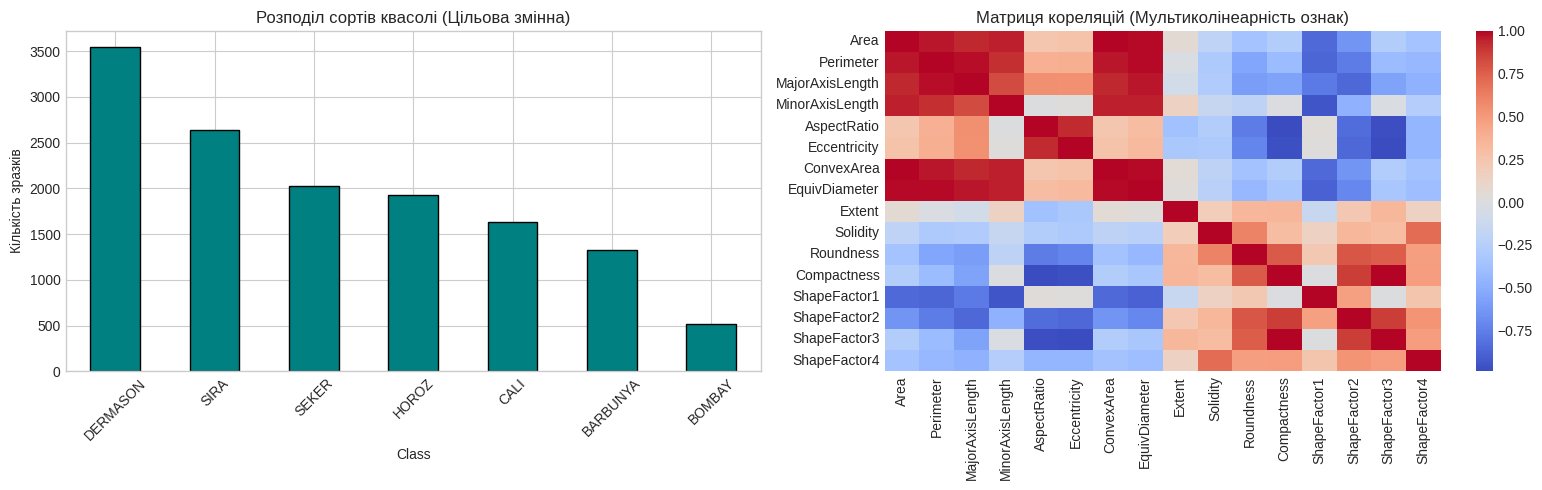

In [ ]:
print("--- Інформація про пропущені значення ---")
print(df.isnull().sum().sum(), "пропущених значень.")

print("\n--- Базові описові статистики ---")
display(df.describe().T[['mean', 'std', 'min', '50%', 'max']])

# Візуалізація розподілу класів та матриці кореляцій
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

df[target_col].value_counts().plot(kind='bar', ax=axes[0], color='teal', edgecolor='black')
axes[0].set_title("Розподіл сортів квасолі (Цільова змінна)")
axes[0].set_ylabel("Кількість зразків")
axes[0].tick_params(axis='x', rotation=45)

num_features = df.select_dtypes(include=[np.number]).columns
corr = df[num_features].corr()
sns.heatmap(corr, cmap='coolwarm', ax=axes[1], cbar=True, annot=False)
axes[1].set_title("Матриця кореляцій (Мультиколінеарність ознак)")

plt.tight_layout()
plt.show()

In [ ]:
# Відбір ознак та формування X і y
X_raw = df.drop(columns=[target_col]).values
classes = np.unique(df[target_col])
class_to_idx = {cls: idx for idx, cls in enumerate(classes)}
y_indices = np.array([class_to_idx[c] for c in df[target_col]])

# 1. Спершу виділяємо Global Test (15%)
X_rem, X_test_raw, y_rem, y_test = train_test_split(
    X_raw, y_indices, test_size=0.15, stratify=y_indices, random_state=SEED
)

# 2. З решти виділяємо Global Validation (~12% від загального пулу)[cite: 64]
val_size_adjusted = 0.12 / 0.85
X_train_pool_raw, X_val_raw, y_train_pool, y_val = train_test_split(
    X_rem, y_rem, test_size=val_size_adjusted, stratify=y_rem, random_state=SEED
)

# 3. Масштабування (fit лише на Train Pool!)
scaler = StandardScaler()
X_train_pool = scaler.fit_transform(X_train_pool_raw) # Тільки трейн навчає скалер[cite: 64]
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

# One-hot кодування для крос-ентропії
num_classes = len(classes)
def to_one_hot(y, C):
    oh = np.zeros((y.size, C))
    oh[np.arange(y.size), y] = 1.0
    return oh

y_train_pool_oh = to_one_hot(y_train_pool, num_classes)
y_val_oh = to_one_hot(y_val, num_classes)
y_test_oh = to_one_hot(y_test, num_classes)

print(f"Розмірності вибірок:")
print(f"• FL Train Pool:     {X_train_pool.shape[0]} зразків ({X_train_pool.shape[0]/len(df)*100:.1f}%)")
print(f"• Global Validation: {X_val.shape[0]} зразків ({X_val.shape[0]/len(df)*100:.1f}%)")
print(f"• Global Test:       {X_test.shape[0]} зразків ({X_test.shape[0]/len(df)*100:.1f}%)")

Розмірності вибірок:
• FL Train Pool:     9935 зразків (73.0%)
• Global Validation: 1634 зразків (12.0%)
• Global Test:       2042 зразків (15.0%)


In [ ]:
class MulticlassLogisticRegression:
    def __init__(self, num_features, num_classes, l2_lambda=0.01):
        self.d = num_features
        self.C = num_classes
        self.l2_lambda = l2_lambda
        # Ініціалізація ваг нулями або малими випадковими числами[cite: 65]
        self.W = np.zeros((self.d, self.C), dtype=np.float64)
        self.b = np.zeros((1, self.C), dtype=np.float64)

    @staticmethod
    def softmax(Z):
        """Чисельно стабільний Softmax (з відніманням максимуму рядка)[cite: 65]."""
        Z_shifted = Z - np.max(Z, axis=1, keepdims=True)
        exp_Z = np.exp(Z_shifted)
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

    def predict_proba(self, X):
        """Обчислення матриці ймовірностей P[cite: 65]."""
        Z = np.dot(X, self.W) + self.b
        return self.softmax(Z)

    def predict(self, X):
        """Передбачення мітки класу."""
        P = self.predict_proba(X)
        return np.argmax(P, axis=1)

    def compute_loss(self, X, Y_oh):
        """Функція втрат із Ridge-регуляризацією (b не регуляризується)[cite: 65]."""
        m = X.shape[0]
        P = self.predict_proba(X)
        eps = 1e-15
        P_clipped = np.clip(P, eps, 1.0 - eps)
        cross_entropy = -np.sum(Y_oh * np.log(P_clipped)) / m
        reg_term = (self.l2_lambda / 2.0) * np.sum(self.W ** 2)
        return cross_entropy + reg_term

    def compute_gradients(self, X_batch, Y_batch_oh):
        """Векторизовані градієнти dW та db без циклів."""
        m = X_batch.shape[0]
        P = self.predict_proba(X_batch)
        error = P - Y_batch_oh # (m, C)[cite: 65]

        # dJ/dW = (1/m) * X.T @ (P - Y) + lambda * W[cite: 65]
        dW = (np.dot(X_batch.T, error) / m) + self.l2_lambda * self.W
        # dJ/db = (1/m) * 1.T @ (P - Y)[cite: 65]
        db = np.sum(error, axis=0, keepdims=True) / m
        return dW, db

    def fit(self, X, Y_oh, epochs=50, lr=0.05, batch_size=64, X_val=None, Y_val_oh=None):
        """Міні-батчевий градієнтний спуск."""
        m = X.shape[0]
        history = {'train_loss': [], 'val_loss': []}

        for epoch in range(epochs):
            indices = np.random.permutation(m)
            X_shuffled = X[indices]
            Y_shuffled = Y_oh[indices]

            for i in range(0, m, batch_size):
                X_b = X_shuffled[i:i + batch_size]
                Y_b = Y_shuffled[i:i + batch_size]

                dW, db = self.compute_gradients(X_b, Y_b)
                self.W -= lr * dW
                self.b -= lr * db

            train_loss = self.compute_loss(X, Y_oh)
            history['train_loss'].append(train_loss)

            if X_val is not None and Y_val_oh is not None:
                val_loss = self.compute_loss(X_val, Y_val_oh)
                history['val_loss'].append(val_loss)

        return history

    def get_params(self):
        """Отримання параметрів моделі (W, b)."""
        return copy.deepcopy(self.W), copy.deepcopy(self.b)

    def set_params(self, W, b):
        """Встановлення параметрів моделі."""
        self.W = copy.deepcopy(W)
        self.b = copy.deepcopy(b)

=== Результати Централізованої моделі на Global Test ===
• accuracy       : 0.9172
• macro_f1       : 0.9303
• balanced_acc   : 0.9280
• log_loss       : 0.2737


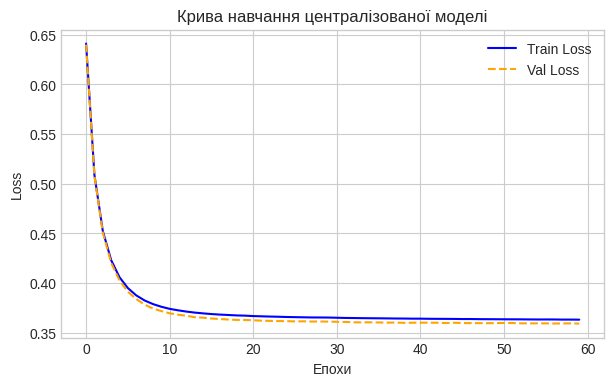

In [ ]:
# Створення та навчання централізованої моделі на всьому FL Train Pool[cite: 66]
central_model = MulticlassLogisticRegression(num_features=X_train_pool.shape[1],
                                             num_classes=num_classes,
                                             l2_lambda=0.005)

hist_central = central_model.fit(
    X=X_train_pool, Y_oh=y_train_pool_oh,
    epochs=60, lr=0.1, batch_size=128,
    X_val=X_val, Y_val_oh=y_val_oh
)

# Функція підрахунку повного комплексу метрик[cite: 66]
def evaluate_metrics(model, X_eval, y_true_idx, y_true_oh):
    y_pred = model.predict(X_eval)
    y_prob = model.predict_proba(X_eval)

    acc = accuracy_score(y_true_idx, y_pred)
    mf1 = f1_score(y_true_idx, y_pred, average='macro')
    b_acc = balanced_accuracy_score(y_true_idx, y_pred)
    ll = log_loss(y_true_idx, y_prob)
    return {
        'accuracy': acc,
        'macro_f1': mf1,
        'balanced_acc': b_acc,
        'log_loss': ll
    }

central_metrics_val = evaluate_metrics(central_model, X_val, y_val, y_val_oh)
central_metrics_test = evaluate_metrics(central_model, X_test, y_test, y_test_oh)

print("=== Результати Централізованої моделі на Global Test ===")
for k, v in central_metrics_test.items():
    print(f"• {k:15s}: {v:.4f}")

# Графік кривих навчання
plt.figure(figsize=(7, 4))
plt.plot(hist_central['train_loss'], label='Train Loss', color='blue')
plt.plot(hist_central['val_loss'], label='Val Loss', color='orange', linestyle='--')
plt.title("Крива навчання централізованої моделі")
plt.xlabel("Епохи")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
def partition_iid(X, y, K, seed=SEED):
    """Стратифікований IID розподіл даних між K клієнтами."""
    np.random.seed(seed)
    client_indices = {k: [] for k in range(K)}
    classes = np.unique(y)

    for c in classes:
        idx_c = np.where(y == c)[0]
        np.random.shuffle(idx_c)
        splits = np.array_split(idx_c, K)
        for k in range(K):
            client_indices[k].extend(splits[k])

    client_data = {}
    for k in range(K):
        idx = np.array(client_indices[k])
        np.random.shuffle(idx)
        client_data[k] = (X[idx], y[idx])
    return client_data


def partition_non_iid_dirichlet(X, y, K, alpha=0.5, seed=SEED):
    """
    Non-IID розподіл за допомогою розподілу Діріхле Dir(alpha)[cite: 68].
    Кожен клас c розподіляється між клієнтами відповідно до пропорцій Dirichlet[cite: 68].
    """
    np.random.seed(seed)
    num_classes = len(np.unique(y))
    client_indices = {k: [] for k in range(K)}

    for c in range(num_classes):
        idx_c = np.where(y == c)[0]
        np.random.shuffle(idx_c)

        # Генерація пропорцій через Dirichlet[cite: 68]
        proportions = np.random.dirichlet(np.repeat(alpha, K))
        # Переведення часток у кількість прикладів
        counts = (proportions * len(idx_c)).astype(int)

        # Корекція похибки заокруглення
        diff = len(idx_c) - counts.sum()
        for i in range(diff):
            counts[i % K] += 1

        start = 0
        for k in range(K):
            end = start + counts[k]
            client_indices[k].extend(idx_c[start:end])
            start = end

    client_data = {}
    for k in range(K):
        idx = np.array(client_indices[k])
        np.random.shuffle(idx)
        client_data[k] = (X[idx], y[idx])
    return client_data

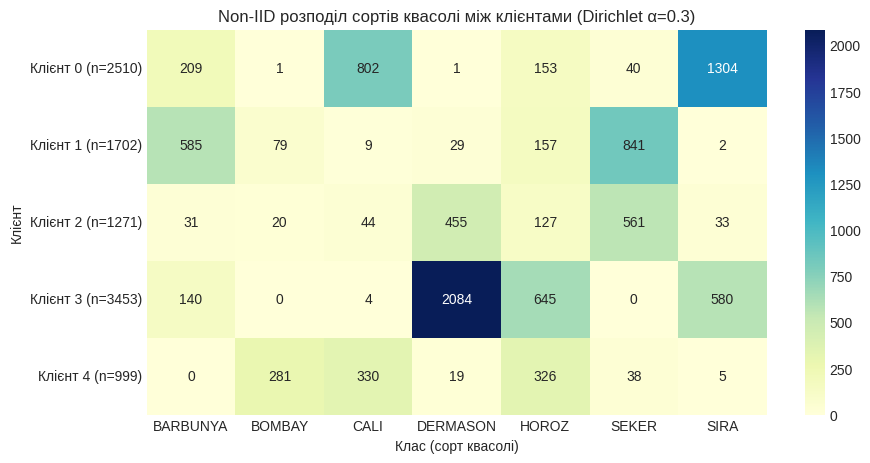

In [ ]:
K_clients = 5
alpha_demo = 0.3
non_iid_clients = partition_non_iid_dirichlet(X_train_pool, y_train_pool, K=K_clients, alpha=alpha_demo)

# Побудова матриці розподілу класів[cite: 68]
dist_matrix = np.zeros((K_clients, num_classes))
for k in range(K_clients):
    _, y_k = non_iid_clients[k]
    for c in range(num_classes):
        dist_matrix[k, c] = np.sum(y_k == c)

plt.figure(figsize=(10, 5))
sns.heatmap(dist_matrix, annot=True, fmt='.0f', cmap='YlGnBu',
            xticklabels=classes, yticklabels=[f"Клієнт {k} (n={len(non_iid_clients[k][1])})" for k in range(K_clients)])
plt.title(f"Non-IID розподіл сортів квасолі між клієнтами (Dirichlet α={alpha_demo})")
plt.xlabel("Клас (сорт квасолі)")
plt.ylabel("Клієнт")
plt.show()

In [ ]:
class FederatedClient:
    """Учасник федеративної мережі, володіє тільки локальними даними."""
    def __init__(self, client_id, X_local, y_local, num_classes, l2_lambda=0.01):
        self.client_id = client_id
        self.X = X_local
        self.y = y_local
        self.y_oh = to_one_hot(y_local, num_classes)
        self.n_samples = len(y_local)
        self.model = MulticlassLogisticRegression(X_local.shape[1], num_classes, l2_lambda=l2_lambda)

    def train(self, global_W, global_b, local_epochs=5, lr=0.05, batch_size=64):
        # 1. Синхронізація з глобальною моделлю[cite: 69]
        self.model.set_params(global_W, global_b)
        # 2. Локальне донавчання на власних даних протягом E епох[cite: 69]
        self.model.fit(self.X, self.y_oh, epochs=local_epochs, lr=lr, batch_size=batch_size)
        # 3. Повернення параметрів клієнта серверу[cite: 69]
        return self.model.get_params()


class FederatedServer:
    """Сервер-агрегатор, зберігає лише Global Validation та Global Test."""
    def __init__(self, num_features, num_classes, l2_lambda=0.01):
        self.global_model = MulticlassLogisticRegression(num_features, num_classes, l2_lambda=l2_lambda)

    def aggregate(self, client_weights, client_sample_sizes):
        """Агрегація FedAvg: зважене середнє параметрів за розмірами вибірок n_k[cite: 69]."""
        total_samples = sum(client_sample_sizes)
        new_W = np.zeros_like(self.global_model.W)
        new_b = np.zeros_like(self.global_model.b)

        for (W_k, b_k), n_k in zip(client_weights, client_sample_sizes):
            weight_ratio = n_k / total_samples
            new_W += weight_ratio * W_k
            new_b += weight_ratio * b_k

        self.global_model.set_params(new_W, new_b)


def run_federated_simulation(client_data_dict, num_features, num_classes,
                             rounds=25, local_epochs=5, lr=0.05, batch_size=64,
                             X_val=None, y_val=None, y_val_oh=None):
    """Повний цикл FedAvg[cite: 69]."""
    K = len(client_data_dict)
    clients = [
        FederatedClient(k, client_data_dict[k][0], client_data_dict[k][1], num_classes)
        for k in range(K)
    ]
    server = FederatedServer(num_features, num_classes)

    round_val_accs = []
    round_val_losses = []

    for r in range(rounds):
        client_updates = []
        sample_sizes = []

        # Поточні параметри глобальної моделі
        g_W, g_b = server.global_model.get_params()

        # Локальне навчання кожного клієнта[cite: 69]
        for client in clients:
            w_k = client.train(g_W, g_b, local_epochs=local_epochs, lr=lr, batch_size=batch_size)
            client_updates.append(w_k)
            sample_sizes.append(client.n_samples)

        # Агрегація FedAvg на сервері[cite: 69]
        server.aggregate(client_updates, sample_sizes)

        # Оцінка на Global Validation[cite: 69]
        val_loss = server.global_model.compute_loss(X_val, y_val_oh)
        val_pred = server.global_model.predict(X_val)
        val_acc = accuracy_score(y_val, val_pred)

        round_val_losses.append(val_loss)
        round_val_accs.append(val_acc)

    return server.global_model, round_val_losses, round_val_accs, clients

=== Запуск Експерименту 1: Вплив неоднорідності даних ===
Завершено: α=5.0 | Test Acc = 0.9153 | Macro F1 = 0.9276
Завершено: α=1.0 | Test Acc = 0.9128 | Macro F1 = 0.9268
Завершено: α=0.3 | Test Acc = 0.8609 | Macro F1 = 0.8153


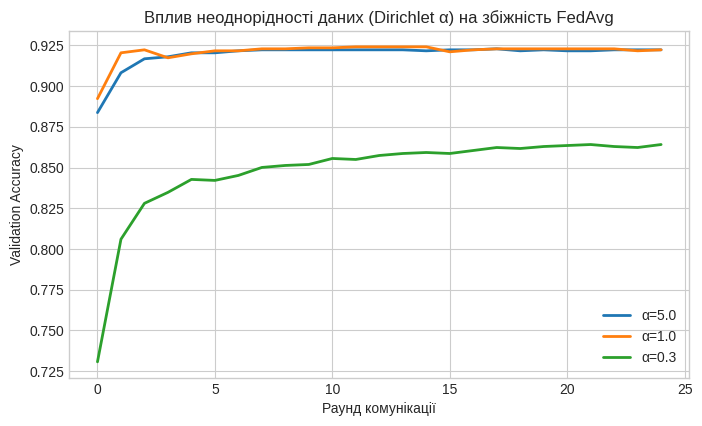

In [ ]:
alphas = [5.0, 1.0, 0.3]
exp1_results = {}
exp1_curves = {}

print("=== Запуск Експерименту 1: Вплив неоднорідності даних ===")
for a in alphas:
    c_data = partition_non_iid_dirichlet(X_train_pool, y_train_pool, K=5, alpha=a, seed=SEED)
    fed_model, val_losses, val_accs, _ = run_federated_simulation(
        c_data, X_train_pool.shape[1], num_classes,
        rounds=25, local_epochs=5, lr=0.08, batch_size=64,
        X_val=X_val, y_val=y_val, y_val_oh=y_val_oh
    )

    # Фінальна оцінка лише на Global Test[cite: 64, 70]
    metrics = evaluate_metrics(fed_model, X_test, y_test, y_test_oh)
    exp1_results[f"Dirichlet α={a}"] = metrics
    exp1_curves[f"α={a}"] = val_accs
    print(f"Завершено: α={a:3.1f} | Test Acc = {metrics['accuracy']:.4f} | Macro F1 = {metrics['macro_f1']:.4f}")

# Графік збіжності за раундами
plt.figure(figsize=(8, 4.5))
for lbl, acc_hist in exp1_curves.items():
    plt.plot(acc_hist, label=lbl, linewidth=2)
plt.title("Вплив неоднорідності даних (Dirichlet α) на збіжність FedAvg")
plt.xlabel("Раунд комунікації")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.show()

=== Запуск Експерименту 2: Вплив кількості локальних епох (при α=0.3) ===
Завершено: E= 1 | Test Acc = 0.8928 | Macro F1 = 0.8792
Завершено: E= 5 | Test Acc = 0.8599 | Macro F1 = 0.8162
Завершено: E=10 | Test Acc = 0.8188 | Macro F1 = 0.7146


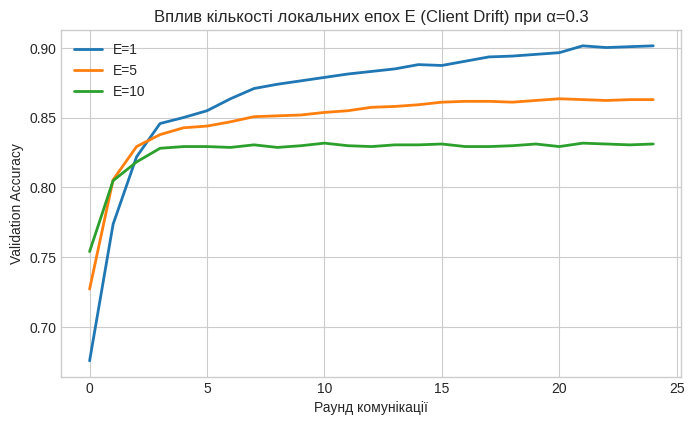

In [ ]:
epochs_list = [1, 5, 10]
exp2_results = {}
exp2_curves = {}

# Беремо Non-IID пул із вираженою неоднорідністю (alpha=0.3)
c_data_non_iid = partition_non_iid_dirichlet(X_train_pool, y_train_pool, K=5, alpha=0.3, seed=SEED)

print("=== Запуск Експерименту 2: Вплив кількості локальних епох (при α=0.3) ===")
for E in epochs_list:
    fed_model, val_losses, val_accs, _ = run_federated_simulation(
        c_data_non_iid, X_train_pool.shape[1], num_classes,
        rounds=25, local_epochs=E, lr=0.08, batch_size=64,
        X_val=X_val, y_val=y_val, y_val_oh=y_val_oh
    )

    metrics = evaluate_metrics(fed_model, X_test, y_test, y_test_oh)
    exp2_results[f"Local E={E}"] = metrics
    exp2_curves[f"E={E}"] = val_accs
    print(f"Завершено: E={E:2d} | Test Acc = {metrics['accuracy']:.4f} | Macro F1 = {metrics['macro_f1']:.4f}")

plt.figure(figsize=(8, 4.5))
for lbl, acc_hist in exp2_curves.items():
    plt.plot(acc_hist, label=lbl, linewidth=2)
plt.title("Вплив кількості локальних епох E (Client Drift) при α=0.3")
plt.xlabel("Раунд комунікації")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.show()

In [ ]:
# Навчання чисто локальних моделей клієнтів (без федеративної агрегації)
local_metrics_list = []
for k in range(5):
    X_k, y_k = c_data_non_iid[k]
    y_k_oh = to_one_hot(y_k, num_classes)
    m_local = MulticlassLogisticRegression(X_k.shape[1], num_classes, l2_lambda=0.01)
    m_local.fit(X_k, y_k_oh, epochs=30, lr=0.08, batch_size=64)
    local_metrics_list.append(evaluate_metrics(m_local, X_test, y_test, y_test_oh))

df_comparison = pd.DataFrame([
    {
        'Модель': 'Централізована (FL Train Pool)',
        **central_metrics_test
    },
    {
        'Модель': 'Глобальна FedAvg (IID-подібна, α=5.0)',
        **exp1_results['Dirichlet α=5.0']
    },
    {
        'Модель': 'Глобальна FedAvg (Non-IID, α=0.3)',
        **exp1_results['Dirichlet α=0.3']
    },
    {
        'Модель': 'Середня суто локальна модель клієнта (Non-IID)',
        'accuracy': np.mean([m['accuracy'] for m in local_metrics_list]),
        'macro_f1': np.mean([m['macro_f1'] for m in local_metrics_list]),
        'balanced_acc': np.mean([m['balanced_acc'] for m in local_metrics_list]),
        'log_loss': np.mean([m['log_loss'] for m in local_metrics_list])
    }
])

print("=== ЗВЕДЕНА ТАБЛИЦЯ ПОРІВНЯННЯ НА GLOBAL TEST ===")
display(df_comparison)

=== ЗВЕДЕНА ТАБЛИЦЯ ПОРІВНЯННЯ НА GLOBAL TEST ===


,Модель,accuracy,macro_f1,balanced_acc,log_loss
0,Централізована (FL Train Pool),0.917238,0.930319,0.927999,0.273653
1,"Глобальна FedAvg (IID-подібна, α=5.0)",0.915279,0.927593,0.924520,0.321278
2,"Глобальна FedAvg (Non-IID, α=0.3)",0.860921,0.815305,0.805697,0.456733
3,Середня суто локальна модель клієнта (Non-IID),0.625759,0.545867,0.638329,1.620516


In [ ]:
print("=== Експеримент Б: Персоналізація глобальної моделі ===")
# Беремо навчену глобальну модель з експерименту α=0.3
final_global_model, _, _, trained_clients = run_federated_simulation(
    c_data_non_iid, X_train_pool.shape[1], num_classes,
    rounds=20, local_epochs=3, lr=0.08, batch_size=64,
    X_val=X_val, y_val=y_val, y_val_oh=y_val_oh
)

g_W, g_b = final_global_model.get_params()
pers_accs = []
glob_on_local_accs = []

for client in trained_clients:
    # 1. Якість глобальної моделі на локальних даних клієнта
    p_glob = final_global_model.predict(client.X)
    glob_on_local_accs.append(accuracy_score(client.y, p_glob))

    # 2. Локальна персоналізація: стартуємо з глобальних ваг і вчимо 2 епохи[cite: 70]
    p_model = MulticlassLogisticRegression(client.X.shape[1], num_classes, l2_lambda=0.01)
    p_model.set_params(g_W, g_b)
    p_model.fit(client.X, client.y_oh, epochs=2, lr=0.05, batch_size=32)

    p_pers = p_model.predict(client.X)
    pers_accs.append(accuracy_score(client.y, p_pers))

df_pers = pd.DataFrame({
    'Клієнт': [f"Клієнт {k}" for k in range(len(trained_clients))],
    'Глобальна модель Acc': glob_on_local_accs,
    'Персоналізована (+2 епохи) Acc': pers_accs
})
display(df_pers)

=== Експеримент Б: Персоналізація глобальної моделі ===


,Клієнт,Глобальна модель Acc,Персоналізована (+2 епохи) Acc
0,Клієнт 0,0.895219,0.951793
1,Клієнт 1,0.886016,0.959459
2,Клієнт 2,0.856019,0.941778
3,Клієнт 3,0.876629,0.935418
4,Клієнт 4,0.793794,0.963964
